# code_212 · Minimize disclosed fields while preserving valid grouping

**Book:** section 40.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_40_GUIDE.md), [execution evidence](../CHAPTER_40_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_212).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evidence contracts identify the protected unit, group denominators, permitted access, threat assumptions and decision responsibility. All household identities and data are generated fixtures. Seeded privacy-noise simulations are reproducible utility demonstrations, not protected releases. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8012;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8012


## Separate necessary grouping from unnecessary identity
 Generate100 fictional households with eight weekly sensor records each, household offset, temperature, exact coordinates, a fictional contact string and proprietary equipment serial. No real person or location is used. A fixed public teaching key generates HMAC household tokens so records remain grouped across time. This demonstrates a deterministic pseudonym; the public demonstration key is not a production secret and the tokens do not anonymize trajectories. Analyst export retains token, week, temperature and response, excluding contact, coordinates and serial. A custodian role can inspect raw fields in this in-memory policy fixture. Unsupported roles are rejected. This is an executable field-policy test, not an operating-system or service IAM boundary. A fixed retention horizon removes raw records older than week4; aggregate model artifacts need a separate retention policy.


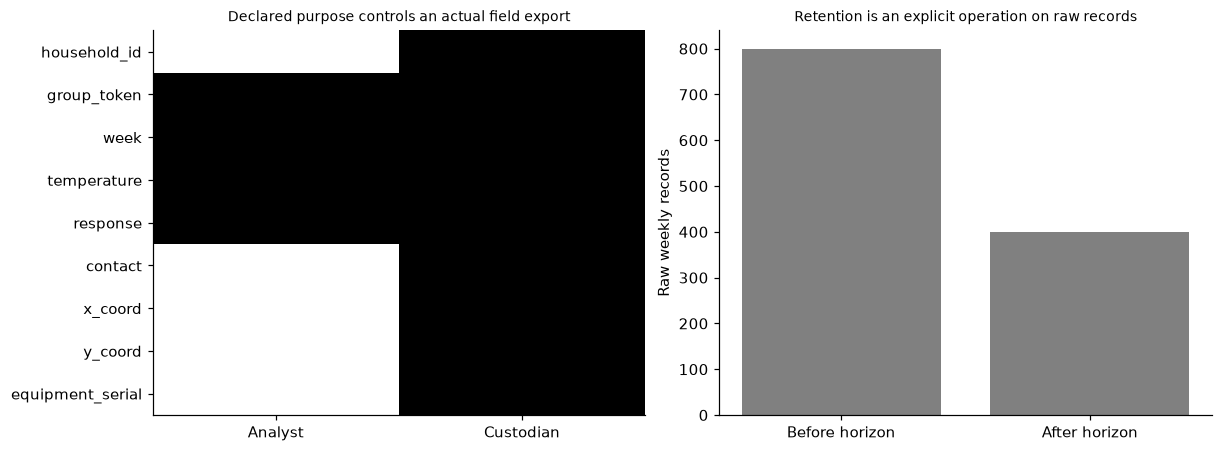

In [2]:
import hashlib,hmac
households=100;weeks=8;ids=np.repeat(np.arange(households),weeks);week=np.tile(np.arange(weeks),households);location=rng.uniform(0,1,(households,2));offset=rng.normal(size=households);temperature=rng.normal(20,3,households*weeks);response=offset[ids]+.2*(temperature-20)+rng.normal(scale=.1,size=len(ids));key=b'PUBLIC-TEACHING-KEY-NOT-A-PRODUCTION-SECRET'
def token(i):return hmac.new(key,f'fictional-household-{i}'.encode(),hashlib.sha256).hexdigest()[:20]
raw=pd.DataFrame({'household_id':ids,'group_token':[token(i) for i in ids],'week':week,'temperature':temperature,'response':response,'contact':[f'fictional-{i}@invalid.example' for i in ids],'x_coord':location[ids,0],'y_coord':location[ids,1],'equipment_serial':[f'PRIVATE-SIM-{i}' for i in ids]});analyst_fields=['group_token','week','temperature','response']
def export(role):
    if role=='analyst':return raw[analyst_fields].copy()
    if role=='custodian':return raw.copy()
    raise PermissionError('Role has no declared export purpose')
shared=export('analyst');denied=False
try:export('unassigned')
except PermissionError:denied=True
assert denied and not {'contact','x_coord','y_coord','equipment_serial','household_id'}&set(shared.columns);assert shared.groupby('group_token').size().eq(8).all();retained=raw[raw.week>=4].copy();assert len(retained)==400 and retained.week.min()==4;RESULTS.update(fictional_households=100,weekly_records=800,analyst_export_fields=analyst_fields,raw_fields=list(raw.columns),retained_raw_records=400,removed_raw_records=400,unsupported_role_rejected=True,grouping_preserved=True,pseudonym_is_not_anonymity=True,public_teaching_key_is_not_secret=True,in_memory_policy_is_not_production_IAM=True);fig,axes=plt.subplots(1,2,figsize=(11,4));allowed=np.array([[int(c in analyst_fields),1] for c in raw.columns]);axes[0].imshow(allowed,cmap='Greys',vmin=0,vmax=1,aspect='auto');axes[0].set(xticks=[0,1],xticklabels=['Analyst','Custodian'],yticks=range(len(raw.columns)),yticklabels=list(raw.columns),title='Declared purpose controls an actual field export');axes[1].bar([0,1],[800,400],color='.5');axes[1].set(xticks=[0,1],xticklabels=['Before horizon','After horizon'],ylabel='Raw weekly records',title='Retention is an explicit operation on raw records');plt.show()


## Test linkage and grouping instead of calling identifiers anonymous
 An auxiliary fictional table knows one household coordinate and identity. Exact coordinate disclosure matches each household uniquely; coarsening both coordinates to a four-by-four grid reduces unique cells but can leave some unique households. Count unique and candidate-set sizes directly. This is one auxiliary-data attack fixture, not a comprehensive reidentification risk estimate or k-anonymity guarantee. Removing all coordinates eliminates this particular join field, not all trajectory linkage. Preserve the household token internally when splitting: first70 households fit, remaining30 assess, so no token appears in both partitions. Contrast with a random-row split whose token overlap exposes repeated-entity mixing. Removing identifiers must not force an invalid random-row evaluation.


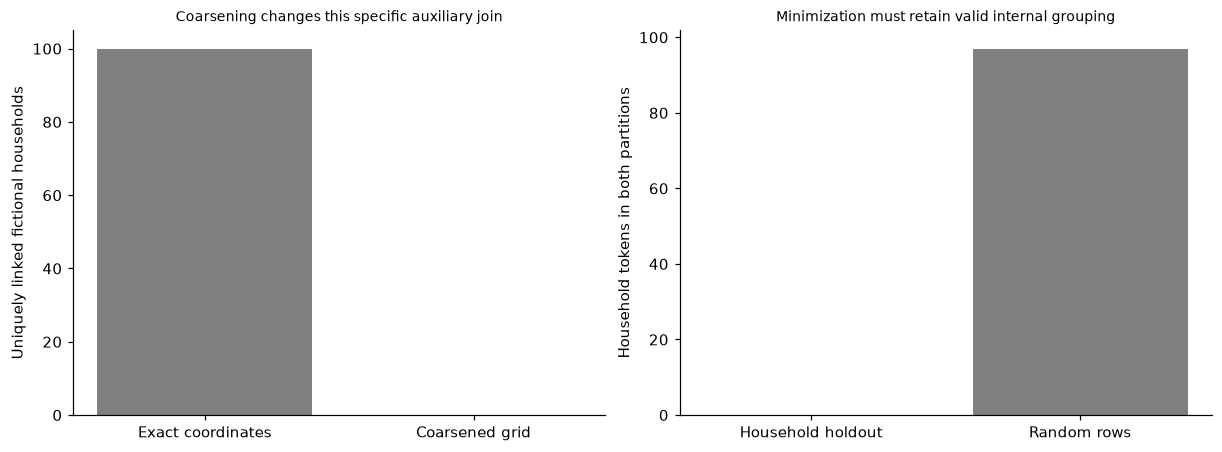

In [3]:
exact=pd.DataFrame(location,columns=['x','y']);coarse=np.floor(location*4).astype(int);cells=pd.DataFrame(coarse,columns=['x','y']);sizes=cells.groupby(['x','y']).size();candidates=np.array([sizes.loc[tuple(row)] for row in coarse]);unique_exact=int(exact.drop_duplicates().shape[0]);unique_coarse=int(np.sum(candidates==1));train_ids=set(shared.loc[ids<70,'group_token']);final_ids=set(shared.loc[ids>=70,'group_token']);assert not train_ids&final_ids;rows=rng.permutation(800);left=set(shared.iloc[rows[:560]].group_token);right=set(shared.iloc[rows[560:]].group_token);overlap=len(left&right);assert overlap>0;RESULTS.update(exact_coordinate_unique_households=unique_exact,coarsened_coordinate_unique_households=unique_coarse,coarse_candidate_set_min=int(candidates.min()),coarse_candidate_set_median=float(np.median(candidates)),group_holdout_token_overlap=0,random_row_split_token_overlap=overlap,coordinate_omission_does_not_prevent_all_linkage=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar([0,1],[unique_exact,unique_coarse],color='.5');axes[0].set(xticks=[0,1],xticklabels=['Exact coordinates','Coarsened grid'],ylabel='Uniquely linked fictional households',title='Coarsening changes this specific auxiliary join');axes[1].bar([0,1],[0,overlap],color='.5');axes[1].set(xticks=[0,1],xticklabels=['Household holdout','Random rows'],ylabel='Household tokens in both partitions',title='Minimization must retain valid internal grouping');plt.show()


In [4]:
summary={'example_id':'code_212','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual household-level pseudonymous grouping with explicit non-anonymity limits', 'purpose and role based field export and retention fixtures', 'auxiliary location-linkage diagnostic before and after coarsening', 'preserved household temporal split rather than random-row mixing'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual household-level pseudonymous grouping with explicit non-anonymity limits", "purpose and role based field export and retention fixtures", "auxiliary location-linkage diagnostic before and after coarsening", "preserved household temporal split rather than random-row mixing"], "elapsed_seconds": 0.168, "example_id": "code_212", "hardware": "Darwin arm64 CPU", "results": {"analyst_export_fields": ["group_token", "week", "temperature", "response"], "coarse_candidate_set_median": 6.0, "coarse_candidate_set_min": 3, "coarsened_coordinate_unique_households": 0, "coordinate_omission_does_not_prevent_all_linkage": true, "exact_coordinate_unique_households": 100, "fictional_households": 100, "group_holdout_token_overlap": 0, "grouping_preserved": true, "in_memory_policy_is_not_production_IAM": true, "pseudonym_is_not_anonymity": true, "public_teaching_key_is_not_secret": true, "random_row_split_token_overlap": 97, "raw_fields": ["household